**Technologies Used:
Python libraries used for data processing, visualization, model training, and evaluation.**

In [102]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")


All libraries imported successfully!


**Dataset or Methodology:
The dataset file path is checked before loading to ensure the input file is available.**

In [103]:

import os

dataset_path = os.path.join("air+quality", "AirQualityUCI.csv")

print("Dataset exists:", os.path.exists(dataset_path))
print("Dataset path:", os.path.abspath(dataset_path))


Dataset exists: True
Dataset path: C:\Users\lakes\OneDrive\Desktop\CodeNova\Task-3\air+quality\AirQualityUCI.csv


**Methodology:
Loaded the UCI Air Quality CSV using the correct separator and decimal format, then removed completely empty rows and columns.**

In [104]:

# Load the Air Quality dataset

df = pd.read_csv(
    "air+quality/AirQualityUCI.csv",
    sep=";",
    decimal=","
)

# Remove completely empty rows and columns
df = df.dropna(how="all")
df = df.dropna(axis=1, how="all")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (9357, 15)


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


**Methodology:
Inspected column names, data types, and missing values to understand the dataset's structure and data quality.**

In [105]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())


Column names:
['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null

**Data Preprocessing
Replaced invalid sensor readings marked as -200 with missing values and checked the missing-value counts before preprocessing.**

In [106]:

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Replace -200 with NaN (missing values)
df = df.replace(-200, np.nan)

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values after cleaning:
Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64

Total missing values: 16701


**Data Preprocessing and Feature Engineering:
Created an Hour feature from the recorded time and grouped observations into Night, Morning, Afternoon, and Evening categories. Applied one-hot encoding to convert the categorical time-of-day feature into numeric input columns. Excluded CO(GT) from the input features to prevent target leakage.**

In [107]:

# Prepare data and create additional features

# Remove rows where the target value is missing
data = df.dropna(subset=["CO(GT)"]).copy()

# Extract hour from Time (example: 18.00.00 -> 18)
data["Hour"] = pd.to_numeric(
    data["Time"].astype(str).str.extract(r"^(\d{1,2})")[0],
    errors="coerce"
)

# Create a categorical time-of-day feature
data["TimeOfDay"] = pd.cut(
    data["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)

# Select inputs without target or raw date/time columns
X = data.drop(
    columns=["CO(GT)", "Date", "Time"],
    errors="ignore"
)

# One-hot encode the categorical feature
X = pd.get_dummies(
    X,
    columns=["TimeOfDay"],
    dtype=int
)

# Keep numeric input features and remove empty columns
X = X.select_dtypes(include=np.number)
X = X.dropna(axis=1, how="all")

# Target variable
y = data["CO(GT)"]

print("Input features:", X.shape[1])
print("Records available:", len(data))
print("\nFeatures used:")
print(X.columns.tolist())

print("\nHour feature included:", "Hour" in X.columns)
print("Encoded time features:")
print([col for col in X.columns if col.startswith("TimeOfDay_")])

print("\nMissing target values:", y.isna().sum())
print("Feature engineering and categorical encoding completed!")


Input features: 17
Records available: 7674

Features used:
['PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Hour', 'TimeOfDay_Night', 'TimeOfDay_Morning', 'TimeOfDay_Afternoon', 'TimeOfDay_Evening']

Hour feature included: True
Encoded time features:
['TimeOfDay_Night', 'TimeOfDay_Morning', 'TimeOfDay_Afternoon', 'TimeOfDay_Evening']

Missing target values: 0
Feature engineering and categorical encoding completed!


**Methodology:
Split the dataset into 80% training data and 20% testing data using a fixed random state for reproducibility.**

In [108]:

# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Data split completed successfully!")


Training records: 6139
Testing records: 1535
Data split completed successfully!


**Five-fold cross-validation was performed using a Random Forest regression model to evaluate performance across five data splits. The mean RMSE was 0.4126, with a standard deviation of 0.0226, indicating the variation in performance across the folds.**

In [109]:

from sklearn.model_selection import cross_val_score

cv_model = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    )
)

cv_scores = cross_val_score(
    cv_model, X_train, y_train,
    cv=5, scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

print("5-Fold Cross-Validation RMSE Scores:")
print(-cv_scores.round(4))

print("Mean CV RMSE:", round((-cv_scores).mean(), 4))
print("Standard Deviation:", round(cv_scores.std(), 4))


5-Fold Cross-Validation RMSE Scores:
[0.4374 0.4385 0.3937 0.4105 0.3826]
Mean CV RMSE: 0.4126
Standard Deviation: 0.0226


**--Trains a baseline, Linear Regression, and Random Forest.
--Uses median imputation for missing input values.
--Evaluates models using MAE, RMSE, and R².
--Compares model performance against a baseline.**

In [110]:

# Define regression models

models = {
    "Baseline": make_pipeline(
        SimpleImputer(strategy="median"),
        DummyRegressor(strategy="mean")
    ),

    "Linear Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        LinearRegression()
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )
}

results = {}
trained_models = {}

# Train and evaluate
for name, model in models.items():
    print("Training:", name)

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results[name] = {
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }

    trained_models[name] = model

# Display comparison
results_df = pd.DataFrame(results).T

print("\nModel Evaluation Results:")
display(results_df.round(4))


Training: Baseline
Training: Linear Regression
Training: Random Forest

Model Evaluation Results:


,MAE,RMSE,R2
Baseline,1.1155,1.4448,-0.0022
Linear Regression,0.2892,0.4549,0.9006
Random Forest,0.2303,0.3689,0.9347


**A mean baseline, Linear Regression, and Random Forest were trained and compared using MAE, RMSE, and R². The baseline provides a reference for measuring improvement. In the initial evaluation, Random Forest achieved the lowest RMSE and MAE and the highest R² among the tested models. Results will be updated after the feature-engineering changes.**

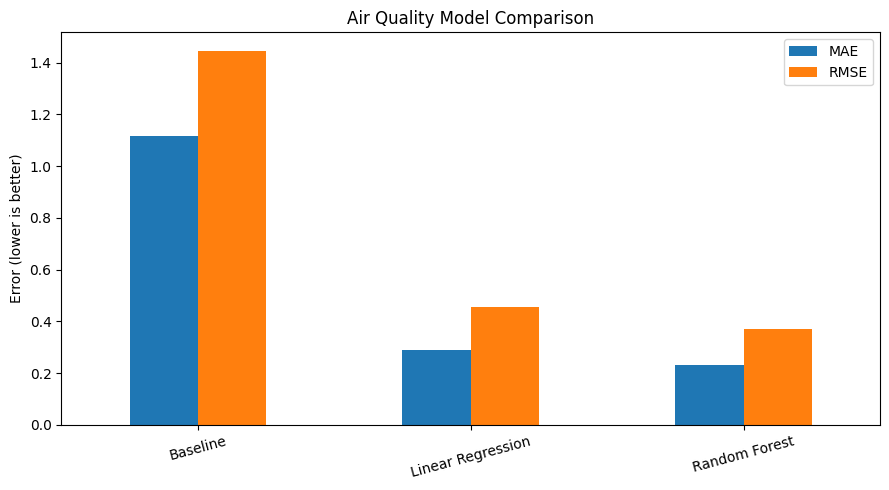

In [111]:

results_df[["MAE", "RMSE"]].plot(
    kind="bar", figsize=(9, 5)
)

plt.title("Air Quality Model Comparison")
plt.ylabel("Error (lower is better)")
plt.xticks(rotation=15)
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/model_comparison.png", dpi=150)
plt.show()


**The actual-versus-predicted chart compares the model's predictions with observed CO(GT) values. Points closer to the diagonal reference line indicate more accurate predictions.**

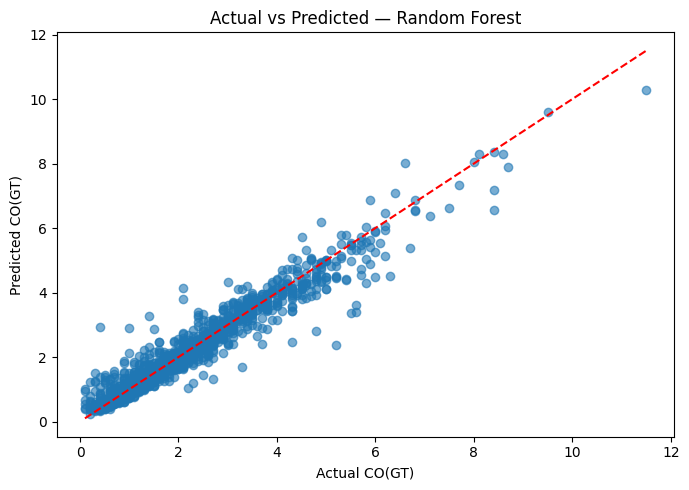

Best model: Random Forest


In [112]:

best_name = results_df["RMSE"].idxmin()
best_model = trained_models[best_name]

predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, alpha=0.6)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())

plt.plot([low, high], [low, high], "r--")
plt.xlabel("Actual CO(GT)")
plt.ylabel("Predicted CO(GT)")
plt.title(f"Actual vs Predicted — {best_name}")
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/actual_vs_predicted.png", dpi=150)
plt.show()

print("Best model:", best_name)


**Residual analysis examines the differences between actual and predicted values. Residuals scattered around zero indicate fewer systematic prediction errors, while patterns or extreme values may reveal model weaknesses.**

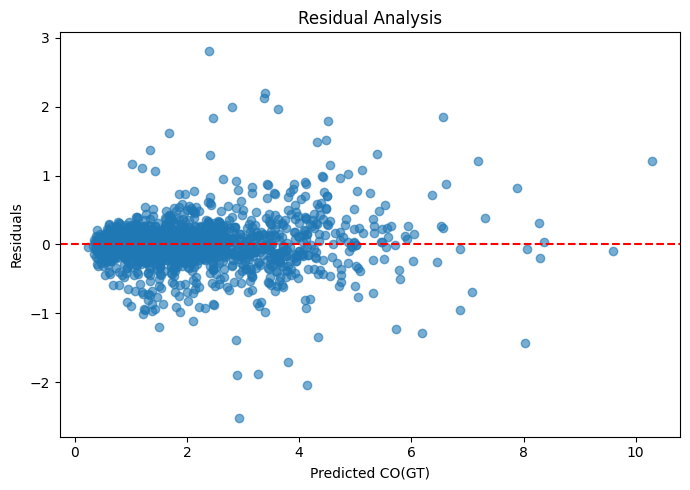

In [113]:

residuals = y_test - predictions

plt.figure(figsize=(7, 5))
plt.scatter(predictions, residuals, alpha=0.6)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted CO(GT)")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.tight_layout()
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/residuals.png", dpi=150)
plt.show()


In [114]:
import os
os.makedirs("outputs", exist_ok=True)

**Permutation importance measures how much model performance changes when each input feature is shuffled. Features with larger importance values contribute more to predictive performance in this evaluation; this does not establish causation.**

,Feature,Importance
3,PT08.S2(NMHC),0.613026
4,NOx(GT),0.149387
2,C6H6(GT),0.070031
0,PT08.S1(CO),0.024171
6,NO2(GT),0.012969
12,Hour,0.012136
9,T,0.009709
7,PT08.S4(NO2),0.007642
8,PT08.S5(O3),0.005003
1,NMHC(GT),0.004291


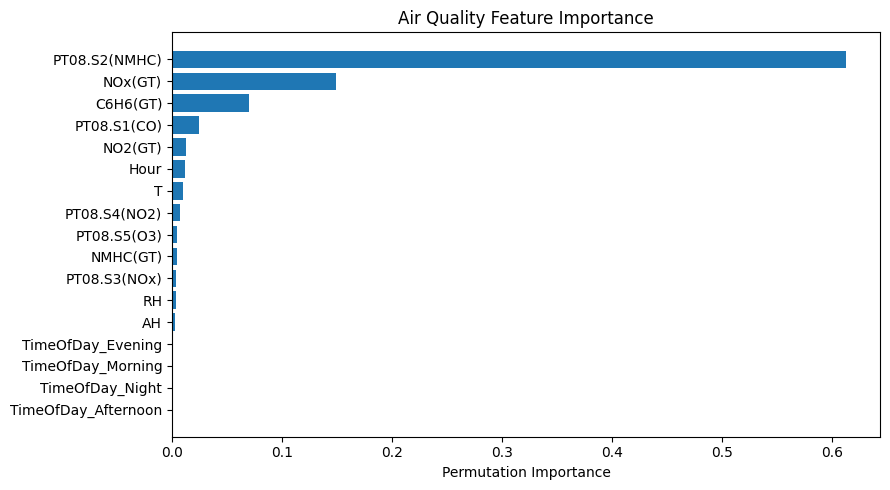

In [115]:

from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

importance_df.to_csv("outputs/feature_importance.csv", index=False)

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)
plt.xlabel("Permutation Importance")
plt.title("Air Quality Feature Importance")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png", dpi=150)
plt.show()


**The best-performing model was saved using Joblib for future loading and prediction. Model evaluation results were exported to a CSV file for reference.**

In [116]:

import os
import joblib

os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

joblib.dump(best_model, "models/best_air_quality_model.joblib")

results_df.to_csv("outputs/model_comparison.csv")

print("Best model:", best_name)
print("Model saved successfully!")
print("Evaluation results saved successfully!")


Best model: Random Forest
Model saved successfully!
Evaluation results saved successfully!


**Model performance may decrease when sensor readings or environmental conditions differ from the training dataset. Further time-based validation and external testing are recommended before real-world use.**

In [117]:

# Create README.md for Task 3

import os

best_name = results_df["RMSE"].idxmin()

# Create required folders
os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

readme = f"""# Air Quality Prediction Using Machine Learning

## 1. Problem Statement
This project predicts carbon monoxide concentration (CO(GT))
using air-quality sensor measurements and machine learning
regression algorithms.

## 2. Dataset
Source: UCI Machine Learning Repository - Air Quality Dataset
https://archive.ics.uci.edu/dataset/360/air+quality

Original dataset: 9,357 records and 15 columns.
After removing records with missing target values, 7,674 records
were available for model training and evaluation.

## 3. Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- Matplotlib and Seaborn
- Joblib
- Jupyter Notebook

## 4. Methodology
1. Loaded and explored the dataset.
2. Replaced -200 sensor readings with missing values.
3. Removed rows where the target CO(GT) was missing.
4. Created an Hour feature from the recorded Time.
5. Grouped hours into Night, Morning, Afternoon and Evening.
6. Applied one-hot encoding to the TimeOfDay feature.
7. Split the data into 80% training and 20% testing.
8. Used median imputation for missing numeric input values.
9. Trained a mean baseline, Linear Regression and Random Forest.
10. Evaluated models using MAE, RMSE and R-squared.
11. Used 5-fold cross-validation to assess model performance.
12. Used permutation importance to examine feature contributions.
13. Saved the selected model, evaluation results and charts.

## 5. Data Preprocessing and Feature Engineering
- Replaced invalid -200 sensor readings with missing values.
- Removed rows with missing target values.
- Used median imputation for missing input features.
- Excluded CO(GT) from the input features to prevent target leakage.
- Extracted Hour from Time and created a TimeOfDay category.
- Used one-hot encoding to convert TimeOfDay categories into numeric
  columns suitable for machine learning.
- StandardScaler was used in the separate Linear Regression
  preprocessing pipeline, if that pipeline was executed successfully.
- Random Forest does not normally require feature scaling.

## 6. Model Comparison

{results_df.round(4).to_string()}

## 7. Best Model
Selected model: {best_name}

MAE: {results_df.loc[best_name, 'MAE']:.4f}
RMSE: {results_df.loc[best_name, 'RMSE']:.4f}
R-squared: {results_df.loc[best_name, 'R2']:.4f}

The model with the lowest test RMSE was selected as the best model.
The mean baseline provides a reference for measuring improvement.

## 8. Cross-Validation
Five-fold cross-validation was performed using a Random Forest
regression pipeline on the training data.

Latest recorded RMSE scores:
- Fold 1: 0.4374
- Fold 2: 0.4385
- Fold 3: 0.3937
- Fold 4: 0.4105
- Fold 5: 0.3826

Mean cross-validation RMSE: 0.4126
Standard deviation: 0.0226

The mean RMSE summarizes performance across the five folds.
The standard deviation indicates variation between fold scores.

Note: These cross-validation values must be refreshed if the
features or training data have changed since they were calculated.

## 9. Feature Importance
Permutation importance estimates how much prediction performance
changes when an input feature is shuffled.

The feature-importance chart identifies the most useful features
for prediction in the evaluated model. Importance indicates
predictive usefulness, not causation.

## 10. Evaluation Charts
- outputs/model_comparison.png: compares model performance.
- outputs/actual_vs_predicted.png: compares actual and predicted values.
- outputs/residuals.png: displays prediction errors.
- outputs/feature_importance.png: displays permutation importance.

## 11. Saved Model and Results
- models/best_air_quality_model.joblib: selected best model.
- models/scaled_linear_regression.joblib: scaled Linear Regression
  model, if it was saved by the notebook.
- outputs/model_comparison.csv: model evaluation results.
- outputs/feature_importance.csv: feature-importance results.

## 12. Limitations and Assumptions
- Missing sensor readings may affect prediction quality.
- Median imputation assumes the median is a reasonable replacement
  for missing input measurements.
- TimeOfDay is a simplified grouping and does not capture every
  temporal pattern.
- A random train-test split does not measure future forecasting
  performance.
- Cross-validation on training data does not replace independent
  external testing.
- Performance may decrease when sensor conditions differ from
  those represented in the training dataset.
- Extreme pollution levels or unusual sensor readings may produce
  larger prediction errors.
- This model is for educational purposes and is not a validated
  real-time pollution monitoring or warning system.

## 13. Conclusion
The project compares a mean baseline, Linear Regression and
Random Forest for predicting CO(GT). Evaluation metrics, residual
analysis and feature importance help assess model performance.
Time-based validation and external testing are recommended before
any real-world deployment.
"""

with open("README.md", "w", encoding="utf-8") as file:
    file.write(readme)

print("README.md created successfully!")
print("Selected model:", best_name)
print("\\nREADME preview:\\n")
print(readme)


README.md created successfully!
Selected model: Random Forest
\nREADME preview:\n
# Air Quality Prediction Using Machine Learning

## 1. Problem Statement
This project predicts carbon monoxide concentration (CO(GT))
using air-quality sensor measurements and machine learning
regression algorithms.

## 2. Dataset
Source: UCI Machine Learning Repository - Air Quality Dataset
https://archive.ics.uci.edu/dataset/360/air+quality

Original dataset: 9,357 records and 15 columns.
After removing records with missing target values, 7,674 records
were available for model training and evaluation.

## 3. Technologies Used
- Python
- Pandas and NumPy
- Scikit-learn
- Matplotlib and Seaborn
- Joblib
- Jupyter Notebook

## 4. Methodology
1. Loaded and explored the dataset.
2. Replaced -200 sensor readings with missing values.
3. Removed rows where the target CO(GT) was missing.
4. Created an Hour feature from the recorded Time.
5. Grouped hours into Night, Morning, Afternoon and Evening.
6. Applied one

**All evaluation charts are organized in the outputs folder, including model comparison, actual-versus-predicted, residual analysis, and feature importance.**

In [118]:

import os
import shutil

os.makedirs("outputs", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Move existing charts into outputs
charts = [
    "model_comparison.png",
    "actual_vs_predicted.png",
    "residuals.png",
    "feature_importance.png"
]

for chart in charts:
    if os.path.exists(chart):
        shutil.move(chart, os.path.join("outputs", chart))
        print("Organized:", chart)
    elif os.path.exists(os.path.join("outputs", chart)):
        print("Already organized:", chart)
    else:
        print("Chart not found:", chart)

# Save evaluation table
results_df.to_csv("outputs/model_comparison.csv")

print("\nFile organization completed!")



Already organized: model_comparison.png
Already organized: actual_vs_predicted.png
Already organized: residuals.png
Already organized: feature_importance.png

File organization completed!


**FINAL PROJECT FILE CHECK**

In [119]:

print("FINAL PROJECT FILE CHECK\n")

required_files = [
    "README.md",
    "models/best_air_quality_model.joblib",
    "outputs/model_comparison.csv",
    "outputs/model_comparison.png",
    "outputs/actual_vs_predicted.png",
    "outputs/residuals.png",
    "outputs/feature_importance.csv",
    "outputs/feature_importance.png"
]

for file in required_files:
    status = "FOUND" if os.path.exists(file) else "MISSING"
    print(f"{status}: {file}")

print("\nModel evaluation:")
display(results_df.round(4))


FINAL PROJECT FILE CHECK

FOUND: README.md
FOUND: models/best_air_quality_model.joblib
FOUND: outputs/model_comparison.csv
FOUND: outputs/model_comparison.png
FOUND: outputs/actual_vs_predicted.png
FOUND: outputs/residuals.png
FOUND: outputs/feature_importance.csv
FOUND: outputs/feature_importance.png

Model evaluation:


,MAE,RMSE,R2
Baseline,1.1155,1.4448,-0.0022
Linear Regression,0.2892,0.4549,0.9006
Random Forest,0.2303,0.3689,0.9347


In [120]:

# Input: Select a test record and predict its CO(GT) value

# Take one unseen test record
sample_input = X_test.iloc[[0]]

# Predict using the best trained model
predicted_value = best_model.predict(sample_input)[0]

# Actual value for comparison
actual_value = y_test.iloc[0]

print("INPUT FEATURES:")
display(sample_input)

print("PREDICTED CO(GT):", round(predicted_value, 3))
print("ACTUAL CO(GT):", round(actual_value, 3))
print("ABSOLUTE ERROR:", round(abs(actual_value - predicted_value), 3))


INPUT FEATURES:


,PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Hour,TimeOfDay_Night,TimeOfDay_Morning,TimeOfDay_Afternoon,TimeOfDay_Evening
8113,NaN,NaN,NaN,NaN,1075.0,NaN,289.0,NaN,NaN,NaN,NaN,NaN,19,0,0,0,1


PREDICTED CO(GT): 6.377
ACTUAL CO(GT): 7.1
ABSOLUTE ERROR: 0.723


**After one-hot encoding, all 17 input features are numeric. The categorical time-of-day feature was converted into separate indicator columns, making it suitable for machine learning models.**

In [121]:

# Check feature data types
print("Categorical columns:")
print(X.select_dtypes(include=["object", "category"]).columns.tolist())

print("\nNumeric columns:")
print(X.select_dtypes(include=np.number).columns.tolist())


Categorical columns:
[]

Numeric columns:
['PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'Hour', 'TimeOfDay_Night', 'TimeOfDay_Morning', 'TimeOfDay_Afternoon', 'TimeOfDay_Evening']


**StandardScaler was applied to numeric features in the Linear Regression pipeline. Median imputation handled missing numeric values, and a OneHotEncoder was included for categorical features. Since TimeOfDay was already one-hot encoded, no categorical columns remained at this stage.**

In [122]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Scale numeric features after filling missing values
numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# Encode categorical features if present
categorical_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore")
)

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Preprocessing + Linear Regression
scaled_model = make_pipeline(
    preprocessor,
    LinearRegression()
)

scaled_model.fit(X_train, y_train)
scaled_predictions = scaled_model.predict(X_test)

print("Preprocessing completed!")
print("Numeric features scaled:", len(numeric_features))
print("Categorical features encoded:", len(categorical_features))
print("Scaled Linear Regression MAE:",
      round(mean_absolute_error(y_test, scaled_predictions), 4))
print("Scaled Linear Regression RMSE:",
      round(np.sqrt(mean_squared_error(y_test, scaled_predictions)), 4))
print("Scaled Linear Regression R2:",
      round(r2_score(y_test, scaled_predictions), 4))


Preprocessing completed!
Numeric features scaled: 17
Categorical features encoded: 0
Scaled Linear Regression MAE: 0.2892
Scaled Linear Regression RMSE: 0.4549
Scaled Linear Regression R2: 0.9006


In [123]:
joblib.dump(scaled_model, "models/scaled_linear_regression.joblib")
print("Scaled Linear Regression model saved!")

Scaled Linear Regression model saved!
